# Blend-system examples

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from functools import lru_cache
from pathlib import Path
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from astropy.visualization import make_lupton_rgb
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.coordinates import SkyCoord
import astropy.units as u

import blend_metrics as bm
from PIL import Image

root = Path('~/lsst_runs').expanduser()
out_dir = Path('paper_plots')
all_wcs = pd.read_csv('/u/yse2/test8k_fns_wcs.csv').set_index('file_name')
out_dir.mkdir(parents=True, exist_ok=True)
mag_limit_val = bm.MAG_LIMITS['gold'] + 2  # buffer 2 
GOLD_CUT = bm.MAG_LIMITS['gold']  # 25.3
NARC = 5 # scalebar length, arcsec (a little tigether than NARC=10 since these are zoomed blend crops)
LINKING_LENGTH = '1.0'

@lru_cache(maxsize=None)
def get_wcs(fn):
    """LSST WCS for one cutout, parsed once per file and cached (parsing the
    header string is the slow part, and many groups share a file)."""
    return WCS(all_wcs.loc[fn, 'wcs'])

def pixel_scale_arcsec(w):
    """Arcsec per pixel under WCS `w`, from the cutout's own WCS rather than
    a hardcoded LSST constant."""
    return proj_plane_pixel_scales(w).mean() * 3600

def scalebar_npix(w, arcsec=NARC):
    """Pixel length of `arcsec` under WCS `w`, from that scene's own pixel
    scale rather than a hardcoded LSST/Roman constant (pixel scale is
    per-tile via the WCS, and the two instruments differ ~3.5x -- see
    blend_viz_README.md)."""
    return int(round(arcsec / pixel_scale_arcsec(w)))

## LSST Pipelines vs. Rubin-only DeepDISC (Rubin30k)

We need to find example significant blend systems showing three outcomes:
- LSST Pipelines fail to separate the blend, Rubin30k resolves it
- Both resolve it
- LSST Pipelines resolve it, Rubin30k does not

We'll search for systems first and then choose a system that we like similar to what we do in `scene_plots.ipynb`.

In [36]:
LSST = dict(prefix='lsst', run='lsst5_30k_4h200_bs192_ep50', combo=None)
RUBIN30K = dict(prefix='dd', run='lsst5_30k_4h200_bs192_ep50', combo='s0.5_n0.6')

MIN_MEMBERS = 2       # a "blend" needs >=2 connected truths by definition
MAX_MEMBERS = 15        # cap so a shortlisted system isn't an enormous crowded group
PAD_PIX = 25           # crop half-width/height around the group centroid, in LSST pixels
N_SHORTLIST = 15 # candidates shown per category

TRUTH_COLS = ['id', 'file_name', 'mag_i', 'group_id', 'ra', 'dec', 'cutout_x', 'cutout_y', 'row_index']
DET_COLS = ['file_name', 'mag_i', 'ra', 'dec', 'cutout_x', 'cutout_y', 'row_index']  # ra/dec: WCS-projected markers in the Roman section

def load_lean(cfg, ll, mag_limit_val):
    """(truths, dets), each trimmed to file_name/mag_i/position columns +
    this pipeline's own blend flags/match columns. Truths keep ra/dec for
    the WCS-based member separation (sep_px). `kp_x`/`kp_y` are only kept
    for the `dd` (Rubin30k) dets -- they don't exist on `lsst` rows, and
    Rubin30k's `dd_det` rows have 100% NaN `cutout_x`/`cutout_y`
    (verified), so kp_x/kp_y is the only usable native-pixel position for
    them."""
    df = bm.load_analysis_df(root / cfg['run'], cfg['prefix'], ll, cfg['combo'], mag_limit_val)
    t, d = bm.split_truth_det(df, cfg['prefix'])
    p = cfg['prefix']
    flag_cols = [f'{p}_is_part_of_blend', f'{p}_is_sig_blend', f'{p}_is_resolved_blend', f'{p}_is_matched']
    t = t[TRUTH_COLS + flag_cols].copy()
    det_cols = DET_COLS + [f'{p}_is_matched', f'{p}_matched_id', f'{p}_is_sig_blend']
    if p == 'dd':
        det_cols += ['kp_x', 'kp_y']
    d = d[det_cols].copy()
    del df
    return t, d

In [3]:
lsst_truths, lsst_dets = load_lean(LSST, LINKING_LENGTH, mag_limit_val)
dd_truths, dd_dets = load_lean(RUBIN30K, LINKING_LENGTH, mag_limit_val)
print(f'lsst_truths: {len(lsst_truths)}, dd_truths: {len(dd_truths)}')

lsst_truths: 470000, dd_truths: 470000


### Qualifying-id sets

`group_id` is NOT comparable across catalogs because FoF is run per pipeline. However, truth `id` *is* a stable cross-catalog key. 

So, we define a candidate blend group as any LSST FoF group that has every one of its truth objects flagged significant in the LSST catalog *AND* the DeepDISC Rubin30k catalog.
<!-- - Must be anchored on one LSST FoF group (`group_id`)
- *EVERY* truth object of that group is *ALSO* independently flagged **significant** in the DD (Rubin30k) catalog -->

In [4]:
lsst_sig_truths = lsst_truths[lsst_truths.lsst_is_part_of_blend & lsst_truths.lsst_is_sig_blend]
lsst_sig_ids = set(lsst_truths.loc[lsst_truths.lsst_is_part_of_blend & lsst_truths.lsst_is_sig_blend, 'id'])
dd_sig_ids = set(dd_truths.loc[dd_truths.dd_is_part_of_blend & dd_truths.dd_is_sig_blend, 'id'])
both_sig_ids = lsst_sig_ids & dd_sig_ids
print(f'lsst_sig_ids: {len(lsst_sig_ids)}, dd_sig_ids: {len(dd_sig_ids)}, both_sig_ids: {len(both_sig_ids)}')
print(f'lsst_sig_truths rows: {len(lsst_sig_truths)}, unique group_ids: {lsst_sig_truths.group_id.nunique()}')

lsst_sig_ids: 67893, dd_sig_ids: 61799, both_sig_ids: 54744
lsst_sig_truths rows: 67893, unique group_ids: 31924


Great! We have ~55k truth objects that are part of significant blend systems of both LSST and DeepDISC. And additionally, from LSST, we have ~32k significant blend groups.

### Finding candidates

For every significant LSST blend group, we ask two questions: did LSST resolve it, and did Rubin30k resolve it? The answers put the group into one of our three categories. `find_candidates()` does this by:

1. **Loop over LSST's significant blend groups.** We `groupby('group_id')` on `lsst_sig_truths` (truths flagged both `is_part_of_blend` and `is_sig_blend` by LSST), so each group is one candidate blend system.
2. **Cut by group size.** Keep only groups with `MIN_MEMBERS <= n <= MAX_MEMBERS` truth objects, since very large groups are too crowded to make a readable example.
3. **Get the Rubin30k verdict.** `dd_verdict` looks up each member's truth `id` in the DD catalog. It returns `True` (resolved), `False` (unresolved), or `None` if any member is not also significant in DD or the members disagree. `None` groups are dropped (and counted in the printout so we know how many were excluded).
4. **Get the LSST verdict.** `is_resolved_blend` is a group-level flag, so every member of an LSST group has the same value and we can read it off the first row.
5. **Assign a category** from the two verdicts:
   - LSST unresolved, Rubin30k resolved -> `top`
   - both resolved -> `middle`
   - LSST resolved, Rubin30k unresolved -> `bottom`
   - both unresolved -> skipped (not one of the outcomes we want to show)
6. **Record properties for picking later.** For each kept group we store the file name, number of members, the largest pairwise pixel separation between members (`sep_px`), and the brightest/faintest `mag_i`. We'll use these to shortlist well-separated, bright systems that are easy to see in a cutout.


In [6]:
dd_res_by_id = dd_truths.set_index('id')['dd_is_resolved_blend']
dd_res_by_id.value_counts()

dd_is_resolved_blend
False    461226
True       8774
Name: count, dtype: int64

In [5]:
def dd_verdict(member_ids):
    """True/False if the DD (Rubin30k) catalog agrees on resolved-status
    for EVERY member id of this LSST group, given that all of them are
    also independently significant in the DD catalog; None (excluded from
    all 3 categories) if any member falls outside both_sig_ids, or the DD
    catalog disagrees across members (a genuine DD-regrouping ambiguity --
    not worth forcing a verdict)."""
    ids = [i for i in member_ids if i in both_sig_ids]
    if len(ids) != len(member_ids) or len(ids) < 2:
        return None
    vals = dd_res_by_id.loc[ids]
    return bool(vals.iloc[0]) if vals.nunique() == 1 else None

In [17]:
def max_sep_px(grp):
    """Largest pairwise angular separation between the group's members
    (from ra/dec), converted to LSST pixels with the cutout's own WCS pixel
    scale."""
    c = SkyCoord(ra=grp['ra'].values * u.deg, dec=grp['dec'].values * u.deg)
    sep_arcsec = c[:, None].separation(c[None, :]).arcsec.max()
    return sep_arcsec / pixel_scale_arcsec(get_wcs(grp['file_name'].iloc[0]))

def find_candidates():
    """One row per qualifying LSST blend group, split into 'top'/'middle'/
    'bottom' by (lsst_is_resolved_blend, dd_verdict). Groups where dd_verdict
    is None (too few/disagreeing DD-side members) are silently excluded --
    reported as a diagnostic count below, not hidden."""
    records = []
    n_excluded = 0
    for gid, grp in lsst_sig_truths.groupby('group_id'):
        n = len(grp)
        if not (MIN_MEMBERS <= n <= MAX_MEMBERS):
            continue
        verdict = dd_verdict(grp['id'].tolist())
        if verdict is None:
            n_excluded += 1
            continue
        lsst_resolved = bool(grp['lsst_is_resolved_blend'].iloc[0])  # group-level, uniform within grp
        if (not lsst_resolved) and verdict:
            category = 'top'
        elif lsst_resolved and verdict:
            category = 'middle'
        elif lsst_resolved and (not verdict):
            category = 'bottom'
        else:
            continue  # both fail -- not one of the 3 requested categories
        records.append(dict(
            category=category, group_id=gid, file_name=grp['file_name'].iloc[0],
            n_members=n, sep_px=max_sep_px(grp),
            mag_bright=grp['mag_i'].min(), mag_faint=grp['mag_i'].max(),
            cx=grp['cutout_x'].mean(), cy=grp['cutout_y'].mean(),  # centroid, for the edge cut + crop
        ))
    print(f'excluded (DD-side too-few/disagreeing members): {n_excluded}')
    return pd.DataFrame(records)

In [18]:
candidates = find_candidates()
print(f'total qualifying groups (any of the 3 categories): {len(candidates)}')

excluded (DD-side too-few/disagreeing members): 6819
total qualifying groups (any of the 3 categories): 2851


In [37]:
SEP_QUANTILE = 0.50  # keep the tightest 10% of each category (smallest sep_px)
EDGE_PAD = PAD_PIX   # centroid must sit at least this many pixels from every image edge,
                     # so the whole crop fits inside the cutout (no clipped thumbnails)
def fits_in_image(row, pad=EDGE_PAD):
    """True if the crop around this group's centroid lies fully inside its
    cutout. Reads only the .npy header (mmap), not the pixel data."""
    H, W = np.load(row.file_name, mmap_mode='r').shape[1:]
    return pad <= row.cx <= W - pad and pad <= row.cy <= H - pad

gold = candidates[candidates.mag_bright < GOLD_CUT]
max_members = gold.n_members.max()

shortlists = {}
for category in ('top', 'middle', 'bottom'):
    sub = gold[gold.category == category]
    # largest group size first; fall back to one fewer if nothing that big survives the edge cut
    for n_target in (max_members, max_members - 1):
        pool = sub[sub.n_members == n_target]
        pool = pool[pool.apply(fits_in_image, axis=1)] if len(pool) else pool
        if len(pool):
            break
    sep_cut = pool.sep_px.quantile(SEP_QUANTILE)
    pool = pool[pool.sep_px <= sep_cut].sort_values('sep_px')
    shortlists[category] = pool
    print(f'{category}: n_members={n_target}, sep_px <= {sep_cut:.2f} -> {len(pool)} shortlisted')

top: n_members=3, sep_px <= 7.16 -> 7 shortlisted
middle: n_members=2, sep_px <= 5.09 -> 7 shortlisted
bottom: n_members=2, sep_px <= 4.94 -> 4 shortlisted


In [34]:
for category in ('top', 'middle', 'bottom'):
    print(f'--- {category} ---')
    display(shortlists[category])

--- top ---


,category,group_id,file_name,n_members,sep_px,mag_bright,mag_faint,cx,cy
1640,top,158159,/u/yse2/lsst_data/truth/51.55_-39.4/c178_51.55...,3,4.791705,24.792297,26.100885,63.717770,68.824285
453,top,44089,/u/yse2/lsst_data/truth/53.26_-40.1/c188_53.26...,3,5.016295,25.298464,26.056313,59.172888,101.555489
2507,top,238229,/u/yse2/lsst_data/truth/53.20_-39.0/c70_53.20_...,3,5.178619,25.251312,26.553631,73.559508,24.231960
478,top,46895,/u/yse2/lsst_data/truth/53.00_-40.6/c135_53.00...,3,5.572249,23.230894,25.742414,62.644300,115.728801
663,top,65774,/u/yse2/lsst_data/truth/53.59_-39.5/c44_53.59_...,3,5.684072,25.295795,26.827497,66.798781,87.500809
2576,top,243725,/u/yse2/lsst_data/truth/52.63_-38.9/c65_52.63_...,3,6.445738,23.742428,25.461561,104.131275,74.426672
50,top,6077,/u/yse2/lsst_data/truth/52.13_-39.5/c65_52.13_...,3,6.656326,25.080559,26.541178,38.874456,42.221422


--- middle ---


,category,group_id,file_name,n_members,sep_px,mag_bright,mag_faint,cx,cy
1398,middle,134324,/u/yse2/lsst_data/truth/51.44_-41.4/c113_51.44...,2,4.334127,24.593128,25.074654,60.566666,52.893023
1602,middle,154244,/u/yse2/lsst_data/truth/53.92_-40.8/c184_53.92...,2,4.544952,25.249802,25.397717,27.509054,96.933716
2014,middle,190100,/u/yse2/lsst_data/truth/52.51_-40.0/c142_52.51...,2,4.695936,24.580717,25.923798,35.522879,71.457504
2611,middle,246892,/u/yse2/lsst_data/truth/52.21_-38.8/c184_52.21...,2,4.766724,25.071457,26.543934,24.024977,43.915944
2109,middle,199733,/u/yse2/lsst_data/truth/51.06_-38.3/c76_51.06_...,2,4.853489,23.448299,24.754139,59.137054,98.873454
1276,middle,124140,/u/yse2/lsst_data/truth/54.09_-40.8/c182_54.09...,2,4.900444,24.856148,25.760870,74.928035,57.237127
966,middle,96235,/u/yse2/lsst_data/truth/52.61_-42.0/c78_52.61_...,2,5.083670,23.996811,25.489361,44.918909,86.319253
70,middle,7899,/u/yse2/lsst_data/truth/53.89_-38.6/c123_53.89...,2,5.086179,25.288675,26.060078,104.314687,84.144393


--- bottom ---


,category,group_id,file_name,n_members,sep_px,mag_bright,mag_faint,cx,cy
390,bottom,37996,/u/yse2/lsst_data/truth/52.83_-38.5/c166_52.83...,2,3.214402,25.240591,26.603836,81.516259,27.734861
645,bottom,64459,/u/yse2/lsst_data/truth/53.39_-39.9/c25_53.39_...,2,3.412600,24.193813,25.946514,126.590651,82.805318
1176,bottom,115234,/u/yse2/lsst_data/truth/53.13_-40.4/c185_53.13...,2,3.961407,24.886078,26.791895,125.250821,98.106041
2321,bottom,219926,/u/yse2/lsst_data/truth/53.96_-41.0/c13_53.96_...,2,4.077483,25.238459,27.180407,123.998162,31.077659
1060,bottom,104633,/u/yse2/lsst_data/truth/53.46_-39.1/c75_53.46_...,2,4.429716,24.205013,25.233124,92.576075,125.783935
2732,bottom,258689,/u/yse2/lsst_data/truth/52.45_-42.0/c13_52.45_...,2,4.790975,25.058407,26.681068,105.175945,114.859027


In [41]:
def make_rgb(img, bands, Q=8):
    """Per-image percentile stretch -- see blend_viz_README.md."""
    r, g, b = img[bands[0]], img[bands[1]], img[bands[2]]
    pmin = np.percentile([r, g, b], 1)
    stretch = np.percentile([r, g, b], 99.5) - pmin
    return make_lupton_rgb(r, g, b, minimum=pmin, stretch=stretch, Q=Q)

def crop_bounds(img_shape_hw, cx, cy, pad_pix=PAD_PIX):
    H, W = img_shape_hw
    x0 = max(0, int(round(cx)) - pad_pix)
    x1 = min(W, int(round(cx)) + pad_pix)
    y0 = max(0, int(round(cy)) - pad_pix)
    y1 = min(H, int(round(cy)) + pad_pix)
    return x0, x1, y0, y1

def group_truths_for(gid):
    return lsst_truths[lsst_truths['group_id'] == gid]

# Marker diameters in points. Smaller than scene_plots.ipynb's (truth 16.5,
# LSST 11, Rubin30k 10): these crops hold only a few objects a few pixels
# apart, so full-scene sizes pile on top of each other. Shadows are drawn
# slightly bigger/thicker underneath each detection marker for contrast.
TRUTH_MS, LSST_MS, DD_MS = 9, 6.5, 6
TRUTH_LW, DET_LW = 1.25, 1.25

def draw_blend_markers(ax, grp, x0, y0):
    """Truth circles (gold solid / buffer dashed, matching scene_plots.ipynb's
    truth_mode='split' convention -- ax.scatter(..., linestyle='--') for the
    dashed style, NOT Line2D, per the dashed-legend-handle gotcha in
    scene_plots_README.md) + LSST (cyan square) and Rubin30k (springgreen x)
    detection markers, each with a black shadow layer for contrast."""
    row_ids = set(grp['row_index'])
    lsst_d = lsst_dets[lsst_dets['lsst_matched_id'].isin(row_ids)]
    dd_d = dd_dets[dd_dets['dd_matched_id'].isin(row_ids)]

    gold = grp[grp['mag_i'] < GOLD_CUT]
    buf = grp[grp['mag_i'] >= GOLD_CUT]
    ax.scatter(gold['cutout_x'] - x0, gold['cutout_y'] - y0, marker='o', s=TRUTH_MS ** 2,
               facecolors='none', edgecolors='white', linewidths=TRUTH_LW)
    ax.scatter(buf['cutout_x'] - x0, buf['cutout_y'] - y0, marker='o', s=TRUTH_MS ** 2,
               facecolors='none', edgecolors='white', linewidths=TRUTH_LW, linestyle='--')

    ax.scatter(lsst_d['cutout_x'] - x0, lsst_d['cutout_y'] - y0, marker='s', s=(LSST_MS + 0.75) ** 2,
               edgecolors='black', facecolors='none', linewidths=DET_LW + 0.5)
    ax.scatter(lsst_d['cutout_x'] - x0, lsst_d['cutout_y'] - y0, marker='s', s=LSST_MS ** 2,
               edgecolors='cyan', facecolors='none', linewidths=DET_LW)

    ax.scatter(dd_d['kp_x'] - x0, dd_d['kp_y'] - y0, marker='x', s=(DD_MS + 0.75) ** 2,
               color='black', linewidths=DET_LW + 1)
    ax.scatter(dd_d['kp_x'] - x0, dd_d['kp_y'] - y0, marker='x', s=DD_MS ** 2,
               color='springgreen', linewidths=DET_LW)

def preview_grid(shortlist, category, cands_per_row=2):
    """Each candidate gets two panels side by side: the bare RGB crop (to
    see what the objects actually look like) and the same crop with truth/
    LSST/Rubin30k markers."""
    n = len(shortlist)
    if n == 0:
        print(f'{category}: no candidates to preview')
        return
    per_row = min(cands_per_row, n)
    nrows = int(np.ceil(n / per_row))
    ncols = 2 * per_row
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.4 * nrows), facecolor='black')
    axes = np.atleast_2d(axes).reshape(nrows, ncols)
    for i, (_, row) in enumerate(shortlist.iterrows()):
        r, c = divmod(i, per_row)
        ax_bare, ax_mark = axes[r, 2 * c], axes[r, 2 * c + 1]
        grp = group_truths_for(row.group_id)
        img = np.load(row.file_name)
        x0, x1, y0, y1 = crop_bounds(img.shape[1:], row.cx, row.cy)
        rgb = make_rgb(img[:, y0:y1, x0:x1], bands=(3, 2, 1))
        for ax in (ax_bare, ax_mark):
            ax.imshow(rgb, origin='lower')
            ax.set_xlim(0, x1 - x0)
            ax.set_ylim(0, y1 - y0)
            ax.axis('off')
        draw_blend_markers(ax_mark, grp, x0, y0)
        ax_bare.set_title(f'gid={row.group_id}  n={row.n_members}  sep={row.sep_px:.1f}px\n'
                          f'i={row.mag_bright:.1f}-{row.mag_faint:.1f}', color='white', fontsize=7)
        ax_mark.set_title('with markers', color='white', fontsize=7)
    for j in range(n, nrows * per_row):
        r, c = divmod(j, per_row)
        axes[r, 2 * c].axis('off')
        axes[r, 2 * c + 1].axis('off')
    fig.suptitle(f'{category} candidates', color='white', fontsize=12)
    plt.tight_layout()
    return fig

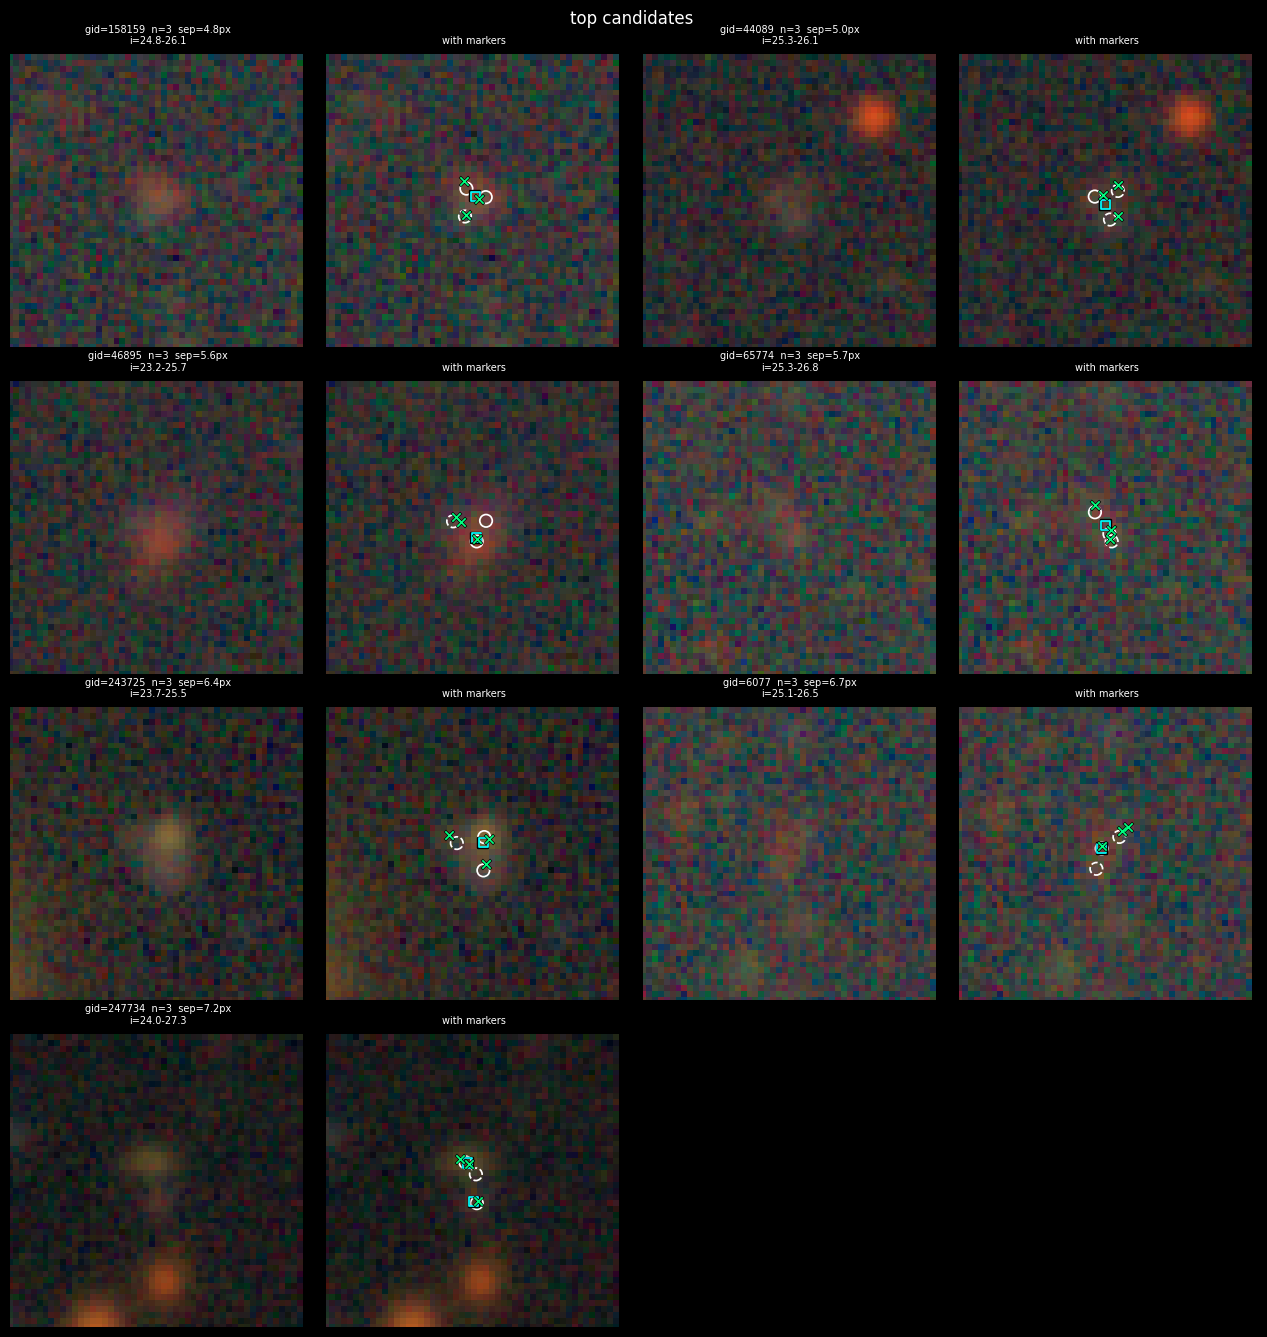

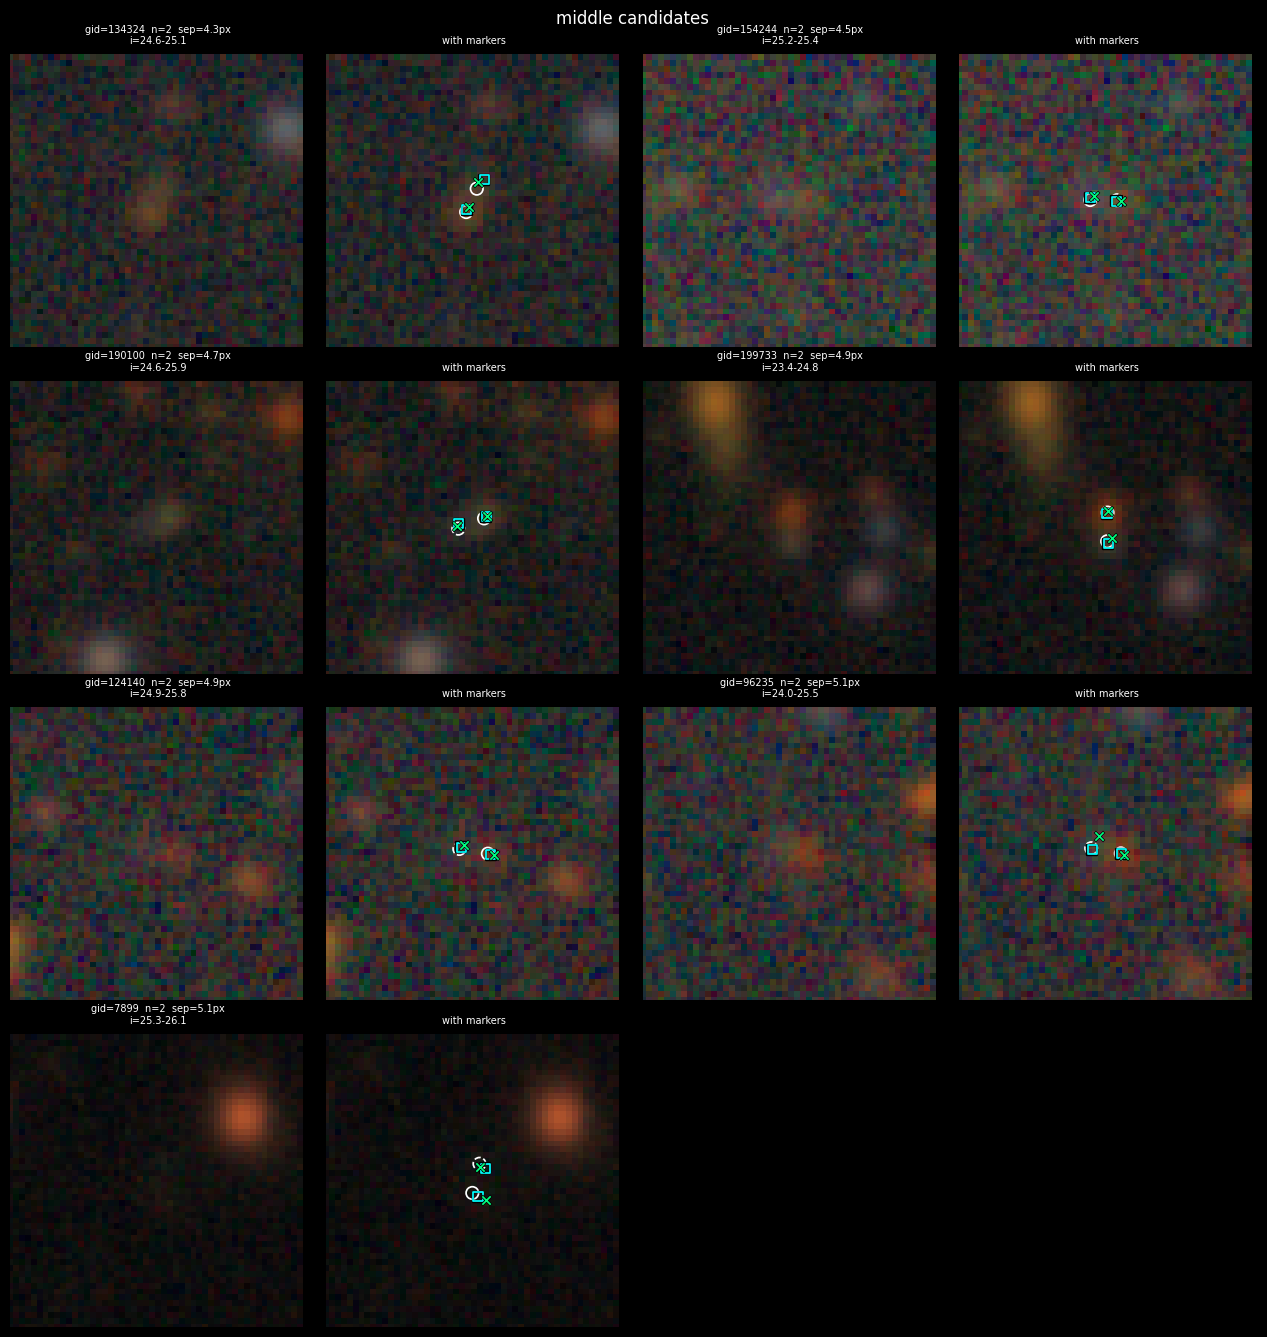

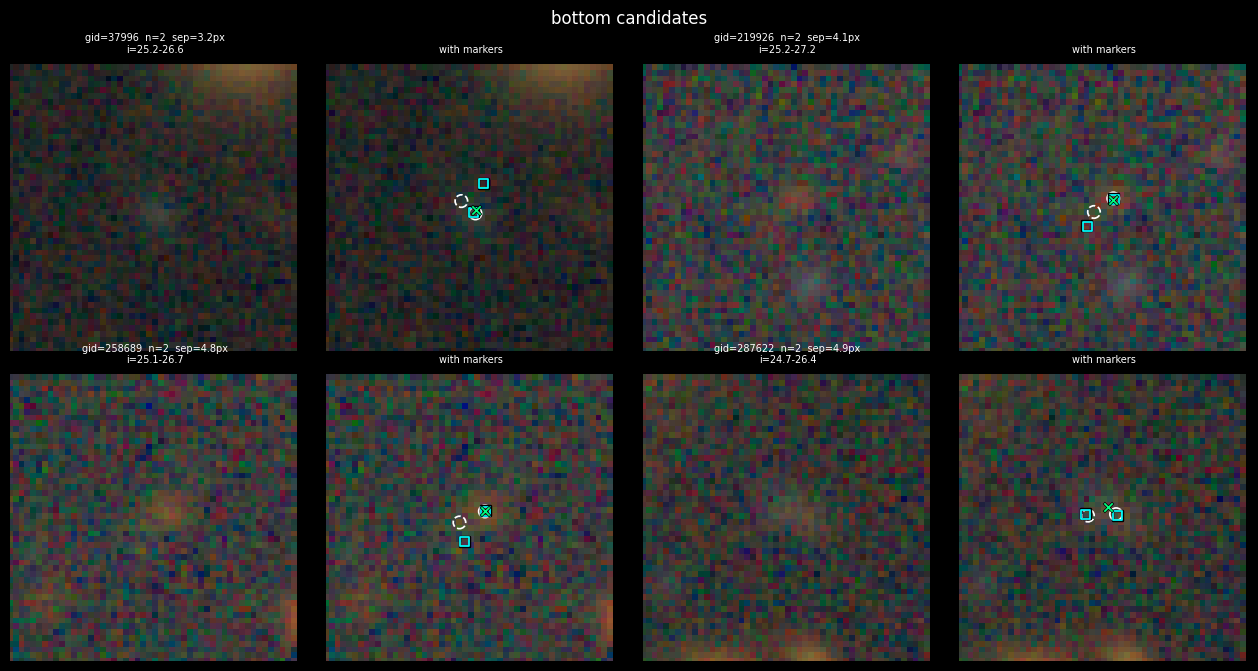

In [40]:
for category in ('top', 'middle', 'bottom'):
    preview_grid(shortlists[category], category)

### Picking a system

In [46]:
from matplotlib.lines import Line2D

CHOSEN = {
    'top': 243725,     # LSST Pipelines fail to separate, Rubin30k resolves
    'middle': 199733,  # both resolve
    'bottom': 287622,  # LSST Pipelines resolve, Rubin30k does not
}
FIGSIZE = (3.5, 3.5)  # small on purpose: marker sizes (TRUTH_MS etc.) are in points,
                      # tuned to look right at the ~3.2" preview panel size

def _savefig_formats(fig, out_path, formats=('png',), dpi=300, **savefig_kwargs):
    """Save `fig` once per extension in `formats` (same as scene_plots.ipynb):
    out_path's own suffix is ignored, each format substitutes its own."""
    paths = []
    for fmt in formats:
        p = Path(out_path).with_suffix(f'.{fmt}')
        fig.savefig(p, dpi=dpi, bbox_inches='tight', **savefig_kwargs)
        paths.append(p)
    return paths

def plot_blend_system(gid, out_path, show_markers=True, formats=('png',), dpi=300):
    """One blend group as its own figure, no title, black background, 5"
    scale bar -- same conventions as scene_plots.ipynb's final figures, so
    rows/panels are arranged in LaTeX rather than baked into one image.
    show_markers=False saves the raw RGB crop only (scale bar kept, so the
    raw panel can stand on its own)."""
    grp = group_truths_for(gid)
    fn = grp['file_name'].iloc[0]
    img = np.load(fn)
    x0, x1, y0, y1 = crop_bounds(img.shape[1:], grp['cutout_x'].mean(), grp['cutout_y'].mean())

    fig, ax = plt.subplots(figsize=FIGSIZE, facecolor='black')
    ax.set_facecolor('black')
    if gid != 287622:
        ax.imshow(make_rgb(img[:, y0:y1, x0:x1], bands=(3, 2, 1)), origin='lower')
    else:
        ax.imshow(make_rgb(img[:, y0:y1, x0:x1], bands=(3, 2, 1), Q=10), origin='lower')
        
    if show_markers:
        draw_blend_markers(ax, grp, x0, y0)
    # lock the view to the crop so no marker can shift it (out-of-bounds
    # autoscale gotcha, see scene_plots_README.md)
    ax.set_xlim(0, x1 - x0)
    ax.set_ylim(0, y1 - y0)
    ax.add_artist(AnchoredSizeBar(
        ax.transData, scalebar_npix(get_wcs(fn)), f'{NARC}"', loc='upper left', pad=0.1,
        color='white', frameon=False, size_vertical=1, fontproperties=fm.FontProperties(size=8)))
    ax.axis('off')
    paths = _savefig_formats(fig, out_path, formats=formats, dpi=dpi)
    plt.close(fig)
    return paths

def _autocrop(path, bg, pad=6):
    """Trim uniform-background margin down to the content's bounding box.
    bbox_inches='tight' can't do this for a legend-only figure -- an Axes
    never shrinks below its own position rectangle (see scene_plots_README.md).
    PNG-only: PIL can't open a PDF as pixels, so PDFs keep their margin."""
    img = Image.open(path).convert('RGB')
    arr = np.array(img)
    mask = np.any(arr != bg, axis=-1)
    if not mask.any():
        return
    rows, cols = np.where(mask)
    box = (max(cols.min() - pad, 0), max(rows.min() - pad, 0),
           min(cols.max() + pad + 1, arr.shape[1]), min(rows.max() + pad + 1, arr.shape[0]))
    img.crop(box).save(path)

def save_blend_legend(out_path, formats=('png',), dpi=300):
    """Standalone legend for the blend figures, using the same (smaller)
    marker sizes as draw_blend_markers. The buffer-truth handle is an empty
    ax.scatter, not a Line2D: Line2D's linestyle dashes a connecting line
    through the marker instead of the marker's own outline (see
    scene_plots_README.md's matplotlib gotchas)."""
    fig, ax = plt.subplots(facecolor='black')
    ax.axis('off')
    handles = [
        Line2D([0], [0], marker='o', markersize=TRUTH_MS, markerfacecolor='none',
               markeredgecolor='white', markeredgewidth=TRUTH_LW, linestyle='None'),
        ax.scatter([], [], marker='o', s=TRUTH_MS ** 2, facecolors='none',
                   edgecolors='white', linewidths=TRUTH_LW, linestyle='--'),
        Line2D([0], [0], marker='s', markersize=LSST_MS, markerfacecolor='none',
               markeredgecolor='cyan', markeredgewidth=DET_LW, linestyle='None'),
        Line2D([0], [0], marker='x', markersize=DD_MS, color='springgreen',
               markeredgewidth=DET_LW, linestyle='None'),
    ]
    labels = ['Ground Truth', 'Ground Truth\n(buffer)', 'LSST Pipelines', 'DeepDISC\nRubin']
    colors = ['white', 'white', 'cyan', 'springgreen']
    leg = ax.legend(handles, labels, loc='center', fontsize=8, facecolor='black',
                    edgecolor='white', framealpha=0.8, ncol=2, columnspacing=0.8,
                    handletextpad=0.5, labelspacing=0.6)
    for text, color in zip(leg.get_texts(), colors):
        text.set_color(color)
    paths = _savefig_formats(fig, out_path, formats=formats, dpi=dpi, facecolor='black')
    plt.close(fig)
    for p in paths:
        if p.suffix == '.png':
            _autocrop(p, bg=(0, 0, 0))
    return paths

In [47]:
for category, gid in CHOSEN.items():
    stem = Path(group_truths_for(gid)['file_name'].iloc[0]).stem  # e.g. c65_52.63_-38.9
    plot_blend_system(gid, out_dir / f'blend_{category}_{stem}_g{gid}.png', formats=('png', 'pdf'))
    plot_blend_system(gid, out_dir / f'blend_{category}_{stem}_g{gid}_raw.png', show_markers=False,
                      formats=('png', 'pdf'))

In [62]:
save_blend_legend(out_dir / 'rubin_only_blend_legend.png', formats=('png', 'pdf'))

[PosixPath('/u/yse2/DeepDISC_Roman_Rubin/paper_plots/rubin_only_blend_legend.png'),
 PosixPath('/u/yse2/DeepDISC_Roman_Rubin/paper_plots/rubin_only_blend_legend.pdf')]

## LSST Pipelines vs. all three DeepDISC models, with Roman imaging

Same search as above, but now every blend gets a verdict from all four catalogs: LSST Pipelines, DeepDISC Rubin (Rubin30k), DeepDISC RubinUps, and DeepDISC Rubin+Roman (Combined). We want:
- **case2_top**: all three Rubin-only catalogs (LSST, Rubin30k, RubinUps) fail to separate the blend, Combined resolves it
- **case2_bottom**: LSST resolves it, Rubin30k and RubinUps do not, Combined resolves it. *No gold candidates exist for this outcome (all 19 are buffer-only), so this one category skips the gold cut.*
- **case3**: LSST resolves it, all three DeepDISC models (including Combined) do not

Each chosen system gets an LSST i/r/g panel with the truths and all four pipelines' detections, plus the matching Roman Y/J/H panel at native resolution (truths only, same as `scene_plots.ipynb`).

In [49]:
RUBINUPS = dict(prefix='dd', run='lsst5_ups_30k_4h200_bs192_ep50', combo='s0.6_n0.65')
COMBINED = dict(prefix='dd', run='comb_30k_4h200_bs144_ep50', combo='s0.6_n0.7')

ups_truths, ups_dets = load_lean(RUBINUPS, LINKING_LENGTH, mag_limit_val)
comb_truths, comb_dets = load_lean(COMBINED, LINKING_LENGTH, mag_limit_val)
print(f'ups_truths: {len(ups_truths)}, comb_truths: {len(comb_truths)}')

# One place to look up each pipeline's catalogs. As in scene_plots.ipynb, only
# Rubin30k's kp_x/kp_y is used directly (LSST panel only); RubinUps/Combined
# keypoints are in the Roman pixel frame (scene_plots_README.md, "kp_x/kp_y
# pixel-frame bug"), so they go through ra/dec + WCS instead.
PIPELINES_ALL = ['LSST', 'Rubin30k', 'RubinUps', 'Combined']
CATS = {
    'LSST':     dict(prefix='lsst', truths=lsst_truths, dets=lsst_dets),
    'Rubin30k': dict(prefix='dd',   truths=dd_truths,   dets=dd_dets),
    'RubinUps': dict(prefix='dd',   truths=ups_truths,  dets=ups_dets),
    'Combined': dict(prefix='dd',   truths=comb_truths, dets=comb_dets),
}

ups_truths: 470000, comb_truths: 470000


### Qualifying-id sets
Same definition as before, extended to four catalogs: every truth in the LSST FoF group must be flagged significant (`is_part_of_blend` & `is_sig_blend`) in **all four** catalogs.

RubinUps and Combined `kp_x`/`kp_y` are in the Roman pixel frame, not LSST's. So, as in `scene_plots.ipynb`, markers are placed by projecting `ra`/`dec` through the WCS of the panel being drawn (that's why `DET_COLS` now includes `ra`/`dec`). The one exception is Rubin30k on the LSST panel, which uses its `kp_x`/`kp_y` directly because they are already in the LSST pixel frame.

In [50]:
sig_ids = {}
for name, c in CATS.items():
    t, p = c['truths'], c['prefix']
    sig_ids[name] = set(t.loc[t[f'{p}_is_part_of_blend'] & t[f'{p}_is_sig_blend'], 'id'])
all4_sig_ids = set.intersection(*sig_ids.values())

# resolved flag per truth id, for the three DeepDISC catalogs (LSST's comes
# straight from its own group, same as above)
res_by_id = {name: c['truths'].set_index('id')[f"{c['prefix']}_is_resolved_blend"]
             for name, c in CATS.items() if name != 'LSST'}

print({name: len(ids) for name, ids in sig_ids.items()})
print(f'significant in all four catalogs: {len(all4_sig_ids)}')

{'LSST': 67893, 'Rubin30k': 61799, 'RubinUps': 61612, 'Combined': 55256}
significant in all four catalogs: 47251


### Finding candidates
Same loop as `find_candidates()`, but `catalog_verdict` is applied to each DeepDISC catalog (Rubin30k, RubinUps, Combined). A group is kept only if each of the three catalogs agrees on the resolved status of every member. The tuple (LSST resolved, Rubin30k, RubinUps, Combined) is then looked up in `ROMAN_CASES` to assign a category. The shortlist uses the same gold cut, largest-group-size, edge, and `SEP_QUANTILE` selection as above. If no candidate at a group size passes, it steps down one member at a time until it reaches `MIN_MEMBERS`.

In [51]:
def catalog_verdict(member_ids, res, sig=all4_sig_ids):
    """dd_verdict generalized to any DeepDISC catalog: True/False if that
    catalog agrees on resolved-status for EVERY member, given that all of
    them are significant in all four catalogs; None (group excluded) if any
    member isn't, or the catalog's own grouping splits the members."""
    if len(member_ids) < 2 or any(i not in sig for i in member_ids):
        return None
    vals = res.loc[member_ids]
    return bool(vals.iloc[0]) if vals.nunique() == 1 else None

# (LSST, Rubin30k, RubinUps, Combined) resolved? -> category
ROMAN_CASES = {
    (False, False, False, True):  'case2_top',     # every Rubin-only catalog fails, Rubin+Roman resolves
    (True,  False, False, True):  'case2_bottom',  # LSST resolves, Rubin-only DeepDISC fail, Rubin+Roman resolves
    (True,  False, False, False): 'case3',         # LSST resolves, all three DeepDISC fail
}

def find_candidates_roman():
    """Same loop as find_candidates, with a verdict from each of the three
    DeepDISC catalogs instead of just Rubin30k."""
    records = []
    n_excluded = 0
    for gid, grp in lsst_sig_truths.groupby('group_id'):
        n = len(grp)
        if not (MIN_MEMBERS <= n <= MAX_MEMBERS):
            continue
        ids = grp['id'].tolist()
        verdicts = [catalog_verdict(ids, res_by_id[name]) for name in ('Rubin30k', 'RubinUps', 'Combined')]
        if None in verdicts:
            n_excluded += 1
            continue
        key = (bool(grp['lsst_is_resolved_blend'].iloc[0]), *verdicts)
        category = ROMAN_CASES.get(key)
        if category is None:
            continue  # an outcome combination we aren't showing
        records.append(dict(
            category=category, group_id=gid, file_name=grp['file_name'].iloc[0],
            n_members=n, sep_px=max_sep_px(grp),
            mag_bright=grp['mag_i'].min(), mag_faint=grp['mag_i'].max(),
            cx=grp['cutout_x'].mean(), cy=grp['cutout_y'].mean(),
        ))
    print(f'excluded (not significant in all four / DeepDISC-side disagreement): {n_excluded}')
    return pd.DataFrame(records)

In [52]:
candidates_roman = find_candidates_roman()
print(candidates_roman.category.value_counts())

excluded (not significant in all four / DeepDISC-side disagreement): 10549
category
case2_top       2556
case3             57
case2_bottom      19
Name: count, dtype: int64


In [74]:
def make_shortlists(cands, categories, no_gold_cut=()):
    """Same selection as the Rubin-only shortlist cell: gold cut on the
    brightest member, largest group size that has any in-bounds candidate,
    then the tightest SEP_QUANTILE of those. Falls back all the way down to
    MIN_MEMBERS (not just max-1), since these outcome combinations are rarer.
    Categories in `no_gold_cut` skip the gold cut (gold+buffer pool instead)."""
    gold = cands[cands.mag_bright < GOLD_CUT]
    max_members = cands.n_members.max()  # start from the overall max; the fallback steps down anyway
    out = {}
    for category in categories:
        pool_src = cands if category in no_gold_cut else gold
        sub = pool_src[pool_src.category == category]
        pool, n_target = sub.iloc[0:0], None
        for n_target in range(max_members, MIN_MEMBERS - 1, -1):
            pool = sub[sub.n_members == n_target]
            pool = pool[pool.apply(fits_in_image, axis=1)] if len(pool) else pool
            if len(pool):
                break
        if len(pool) == 0:
            print(f'{category}: no {"" if category in no_gold_cut else "gold, "}in-bounds candidates')
            out[category] = pool
            continue
        sep_cut = pool.sep_px.quantile(SEP_QUANTILE)
        pool = pool[pool.sep_px <= sep_cut].sort_values('sep_px')
        out[category] = pool
        print(f'{category}: n_members={n_target}, sep_px <= {sep_cut:.2f} -> {len(pool)} shortlisted')
    return out

ROMAN_CATEGORIES = ('case2_top', 'case2_bottom', 'case3')
# case2_bottom has no gold candidates at all: every one of its 19 groups is
# buffer-only (brightest member i = 25.31-26.33), so it's shortlisted from the
# gold+buffer pool instead -- the chosen system is a faint, buffer-magnitude one.
shortlists_roman = make_shortlists(candidates_roman, ROMAN_CATEGORIES, no_gold_cut=('case2_bottom',))

case2_top: n_members=3, sep_px <= 6.21 -> 14 shortlisted
case2_bottom: n_members=2, sep_px <= 4.24 -> 3 shortlisted
case3: n_members=2, sep_px <= 4.08 -> 2 shortlisted


In [75]:
for category in ROMAN_CATEGORIES:
    print(f'--- {category} ---')
    display(shortlists_roman[category])

--- case2_top ---


,category,group_id,file_name,n_members,sep_px,mag_bright,mag_faint,cx,cy
506,case2_top,54524,/u/yse2/lsst_data/truth/53.20_-39.0/c219_53.20...,3,3.635554,22.645494,25.488508,76.565572,59.695902
1538,case2_top,159369,/u/yse2/lsst_data/truth/52.44_-41.4/c113_52.44...,3,3.663705,22.806446,26.622761,120.719951,102.052397
1463,case2_top,153298,/u/yse2/lsst_data/truth/53.04_-39.0/c151_53.04...,3,4.096978,23.725349,26.440449,35.957013,56.546753
784,case2_top,82505,/u/yse2/lsst_data/truth/54.25_-40.8/c135_54.25...,3,4.145518,25.072853,25.976547,80.524272,98.664368
930,case2_top,97281,/u/yse2/lsst_data/truth/51.44_-41.4/c21_51.44_...,3,4.396224,23.268970,25.610386,92.666236,52.274976
2036,case2_top,208044,/u/yse2/lsst_data/truth/53.39_-39.3/c45_53.39_...,3,4.571040,22.467388,26.266380,74.336086,110.082143
2137,case2_top,217577,/u/yse2/lsst_data/truth/53.39_-40.5/c104_53.39...,3,4.739206,24.727741,26.514126,50.815818,100.804487
294,case2_top,31365,/u/yse2/lsst_data/truth/52.68_-41.9/c97_52.68_...,3,5.046386,24.805664,26.301105,27.219833,102.285352
1290,case2_top,134896,/u/yse2/lsst_data/truth/52.95_-38.9/c80_52.95_...,3,5.143776,23.506746,25.937902,85.997120,28.055053
635,case2_top,67642,/u/yse2/lsst_data/truth/52.00_-41.3/c171_52.00...,3,5.524375,25.081104,27.205978,70.052874,32.518644


--- case2_bottom ---


,category,group_id,file_name,n_members,sep_px,mag_bright,mag_faint,cx,cy
1219,case2_bottom,126190,/u/yse2/lsst_data/truth/54.46_-41.0/c35_54.46_...,2,3.034450,25.905525,26.236588,105.009137,106.554994
335,case2_bottom,36042,/u/yse2/lsst_data/truth/52.60_-38.6/c102_52.60...,2,4.130459,25.771500,26.890173,119.635683,49.311158
1145,case2_bottom,118642,/u/yse2/lsst_data/truth/51.67_-41.9/c32_51.67_...,2,4.214663,26.269581,26.667767,45.775836,88.895482


--- case3 ---


,category,group_id,file_name,n_members,sep_px,mag_bright,mag_faint,cx,cy
350,case3,37996,/u/yse2/lsst_data/truth/52.83_-38.5/c166_52.83...,2,3.214402,25.240591,26.603836,81.516259,27.734861
2168,case3,219926,/u/yse2/lsst_data/truth/53.96_-41.0/c13_53.96_...,2,4.077483,25.238459,27.180407,123.998162,31.077659


In [79]:
from plot_binned_metrics import RUN_COLORS

# Marker style per pipeline, same shapes/colors as scene_plots.ipynb, at the
# smaller blend-crop sizes (RubinUps/Combined scaled down from the scene's
# 8.25/8 by the same factor as Rubin30k's 10 -> DD_MS).
RUBINUPS_MS, COMB_MS = 5, 5.5
PIPE_STYLE = {
    'LSST':     dict(marker='s', color='cyan',        ms=LSST_MS),
    'Rubin30k': dict(marker='x', color='springgreen', ms=DD_MS),
    'RubinUps': dict(marker='D', color='yellow',      ms=RUBINUPS_MS),
    'Combined': dict(marker='+', color=RUN_COLORS[2], ms=COMB_MS),
}
LINE_ONLY = {'x', '+'}  # need color=, not edgecolors/facecolors (blend_viz_README.md)
LEGEND_NAMES = {'LSST': 'LSST Pipelines', 'Rubin30k': 'DeepDISC\nRubin',
                'RubinUps': 'DeepDISC\nRubinUps', 'Combined': 'DeepDISC\nRubin+Roman'}

@lru_cache(maxsize=None)
def get_wcs_roman(fn):
    """Roman WCS for the Roman cutout matching LSST cutout `fn`."""
    return WCS(all_wcs.loc[fn, 'wcs_roman'])

def to_pix(df, w):
    c = SkyCoord(ra=df['ra'].values * u.deg, dec=df['dec'].values * u.deg)
    return w.world_to_pixel(c)

def group_dets(name, grp):
    """This pipeline's detections matched to the group's truths. Joined through
    the pipeline's OWN truth rows (by truth id), since matched_id points at a
    row_index in that pipeline's catalog."""
    c, p = CATS[name], CATS[name]['prefix']
    rows = set(c['truths'].loc[c['truths']['id'].isin(grp['id']), 'row_index'])
    return c['dets'][c['dets'][f'{p}_matched_id'].isin(rows)]

def draw_markers_4(ax, grp, w, x0, y0, pipelines=PIPELINES_ALL, native_kp_pipelines=()):
    """Truth circles (gold solid / buffer dashed) + detection markers for the
    given pipelines, projected through ra/dec + WCS `w` (works for both the
    LSST and the Roman frame). Black shadow under each detection marker.
    native_kp_pipelines: labels whose kp_x/kp_y already sit in THIS panel's
    pixel frame -- scattered directly instead of via the WCS, same as
    scene_plots.ipynb's draw_markers. Only Rubin30k on the LSST panel
    qualifies (RubinUps/Combined kp_x/kp_y are Roman-frame, see
    scene_plots_README.md's "kp_x/kp_y pixel-frame bug")."""
    for sub, ls in ((grp[grp['mag_i'] < GOLD_CUT], '-'), (grp[grp['mag_i'] >= GOLD_CUT], '--')):
        x, y = to_pix(sub, w)
        ax.scatter(x - x0, y - y0, marker='o', s=TRUTH_MS ** 2, facecolors='none',
                   edgecolors='white', linewidths=TRUTH_LW, linestyle=ls)
    for name in pipelines:
        st = PIPE_STYLE[name]
        d = group_dets(name, grp)
        x, y = (d['kp_x'].values, d['kp_y'].values) if name in native_kp_pipelines else to_pix(d, w)
        x, y = x - x0, y - y0
        if st['marker'] in LINE_ONLY:
            ax.scatter(x, y, marker=st['marker'], s=(st['ms'] + 0.75) ** 2, color='black', linewidths=DET_LW + 1)
            ax.scatter(x, y, marker=st['marker'], s=st['ms'] ** 2, color=st['color'], linewidths=DET_LW)
        else:
            ax.scatter(x, y, marker=st['marker'], s=(st['ms'] + 0.75) ** 2, edgecolors='black',
                       facecolors='none', linewidths=DET_LW + 0.5)
            ax.scatter(x, y, marker=st['marker'], s=st['ms'] ** 2, edgecolors=st['color'],
                       facecolors='none', linewidths=DET_LW)

def render_blend(ax, gid, frame='lsst', show_markers=True, pipelines=PIPELINES_ALL):
    """Draw one blend group's crop onto `ax`, in the LSST frame (i/r/g) or the
    Roman frame (H/J/Y, native resolution). The Roman crop covers the same
    patch of sky: centered on the members' ra/dec, with PAD_PIX rescaled by
    the LSST/Roman pixel-scale ratio (~3.5x). Axes are locked to the crop."""
    grp = group_truths_for(gid)
    fn = grp['file_name'].iloc[0]
    w_lsst = get_wcs(fn)
    if frame == 'lsst':
        img, w, bands, pad, Q = np.load(fn), w_lsst, (3, 2, 1), PAD_PIX, 8
    else:
        w = get_wcs_roman(fn)
        img, bands, Q = np.load(fn.replace('lsst_data', 'roman_data')), (2, 1, 0), 10  # Roman stretch uses Q=10
        pad = int(round(PAD_PIX * pixel_scale_arcsec(w_lsst) / pixel_scale_arcsec(w)))
    gx, gy = to_pix(grp, w)
    x0, x1, y0, y1 = crop_bounds(img.shape[1:], gx.mean(), gy.mean(), pad)
    ax.set_facecolor('black')
    ax.imshow(make_rgb(img[:, y0:y1, x0:x1], bands=bands, Q=Q), origin='lower')
    if show_markers:
        draw_markers_4(ax, grp, w, x0, y0, pipelines,
                       native_kp_pipelines=('Rubin30k',) if frame == 'lsst' else ())
    ax.set_xlim(0, x1 - x0)
    ax.set_ylim(0, y1 - y0)
    ax.axis('off')
    return fn, w

def preview_grid_roman(shortlist, category):
    """One row per candidate: LSST raw | LSST with truths + all four pipelines |
    Roman with truths (the Roman panel shows truths only, as in scene_plots)."""
    n = len(shortlist)
    if n == 0:
        print(f'{category}: no candidates to preview')
        return
    fig, axes = plt.subplots(n, 3, figsize=(9.6, 3.4 * n), facecolor='black')
    axes = np.atleast_2d(axes)
    for i, (_, row) in enumerate(shortlist.iterrows()):
        render_blend(axes[i, 0], row.group_id, 'lsst', show_markers=False)
        render_blend(axes[i, 1], row.group_id, 'lsst')
        render_blend(axes[i, 2], row.group_id, 'roman', pipelines=())
        axes[i, 0].set_title(f'gid={row.group_id}  n={row.n_members}  sep={row.sep_px:.1f}px\n'
                             f'i={row.mag_bright:.1f}-{row.mag_faint:.1f}', color='white', fontsize=7)
        axes[i, 1].set_title('LSST + all four pipelines', color='white', fontsize=7)
        axes[i, 2].set_title('Roman + truths', color='white', fontsize=7)
    fig.suptitle(f'{category} candidates', color='white', fontsize=12)
    plt.tight_layout()
    return fig

In [ ]:
sub = candidates_roman[candidates_roman.category == 'case2_bottom'].copy()
sub['gold'] = sub.mag_bright < GOLD_CUT
sub['in_bounds'] = sub.apply(fits_in_image, axis=1)
print(sub[['gold', 'in_bounds']].value_counts())
sub.sort_values('sep_px')[['group_id', 'n_members', 'sep_px', 'mag_bright', 'mag_faint', 'gold', 'in_bounds']]

gold   in_bounds
False  False        13
       True          6
Name: count, dtype: int64


,group_id,n_members,sep_px,mag_bright,mag_faint,gold,in_bounds
1469,153799,2,1.550376,25.833408,26.348303,False,False
1219,126190,2,3.034450,25.905525,26.236588,False,True
2190,222060,2,3.505094,25.962883,26.332355,False,False
2231,225854,2,3.700677,25.602951,25.999657,False,False
335,36042,2,4.130459,25.771500,26.890173,False,True
1801,182684,2,4.212549,26.158405,27.252808,False,False
1145,118642,2,4.214663,26.269581,26.667767,False,True
1475,154041,2,4.240682,25.328598,26.850067,False,False
1684,172989,2,4.272221,25.949188,26.329418,False,True
325,34910,2,4.456105,25.916042,26.116934,False,False


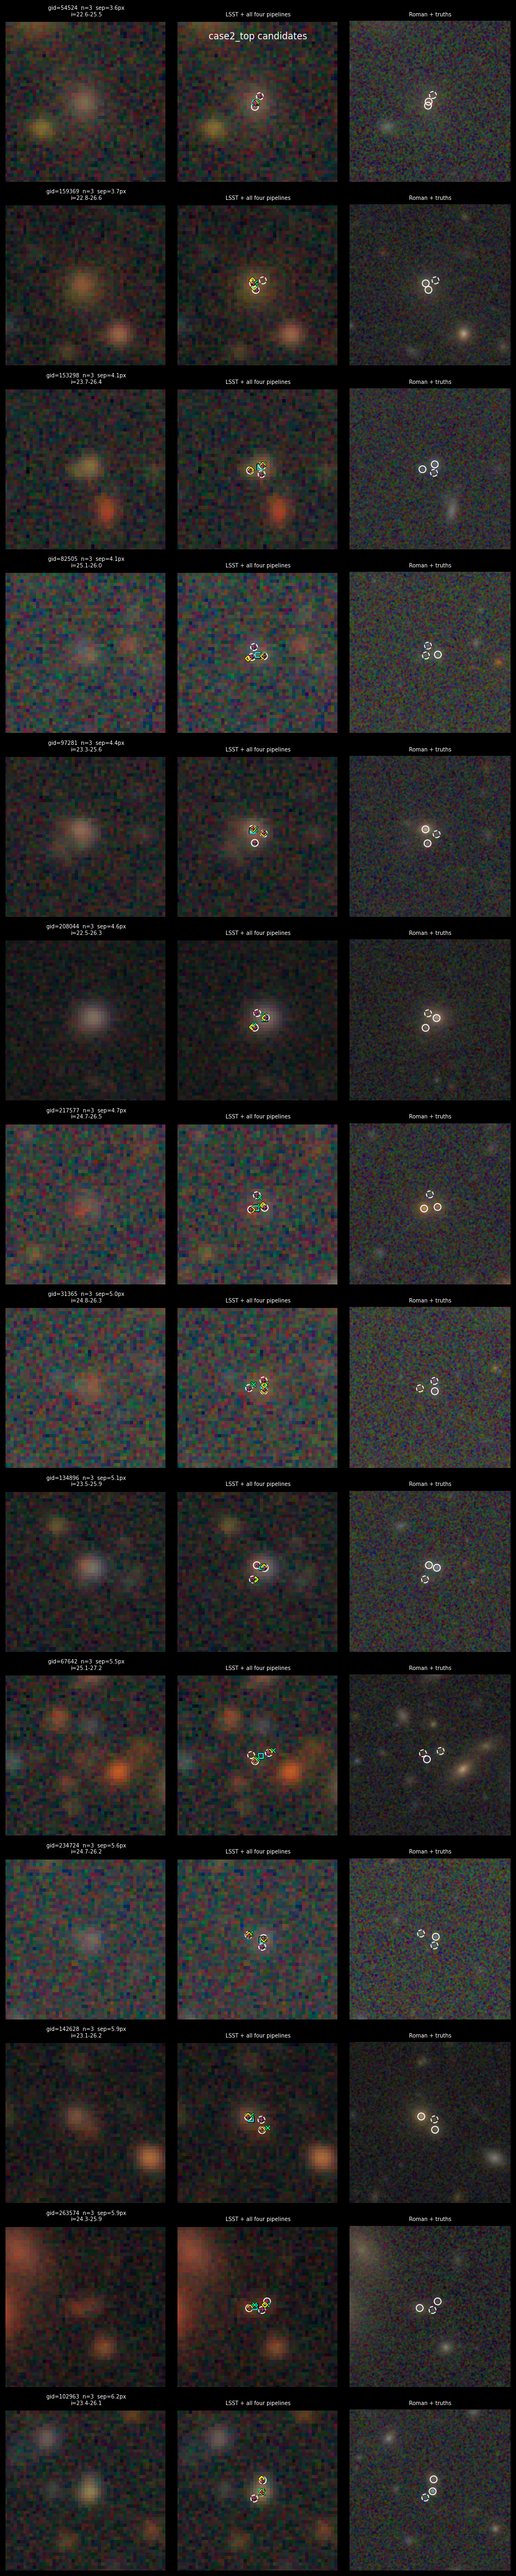

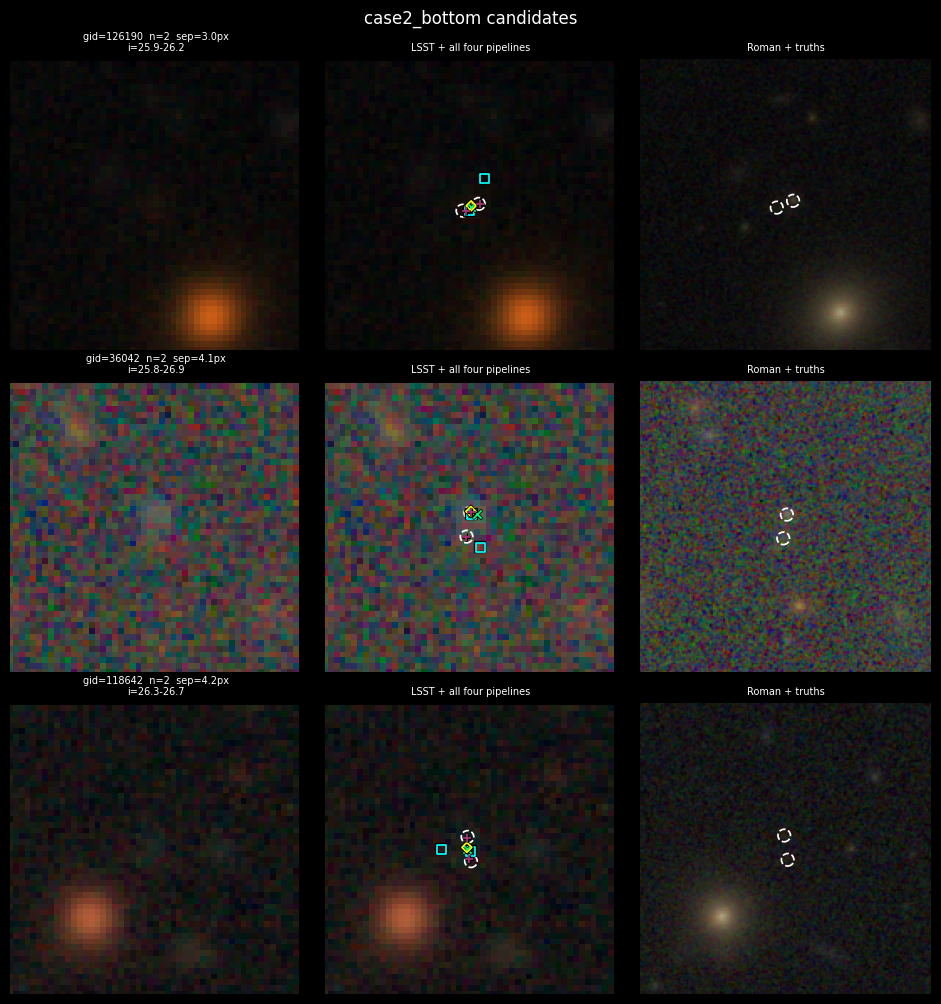

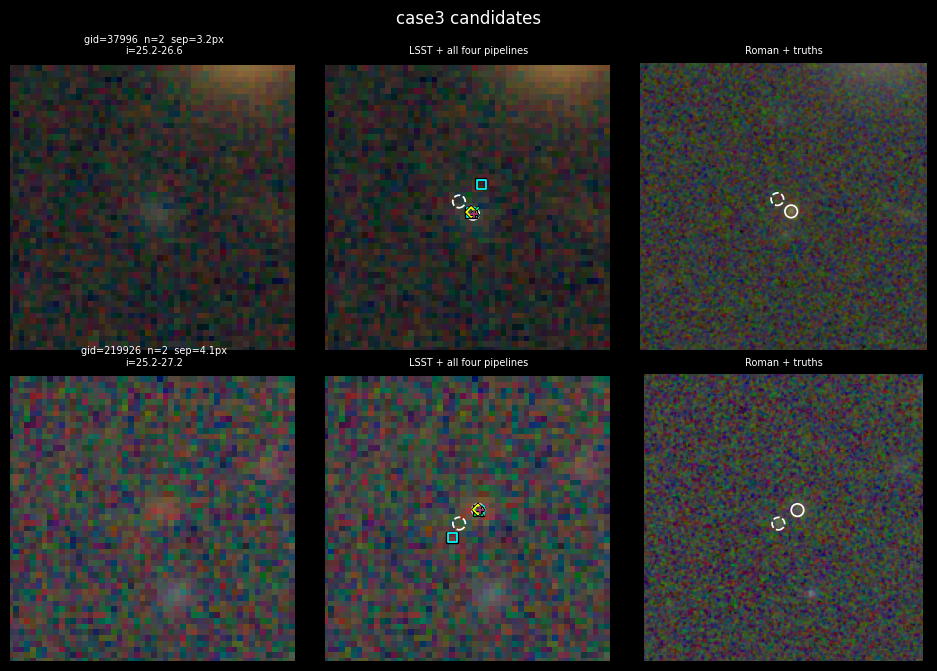

In [81]:
for category in ROMAN_CATEGORIES:
    preview_grid_roman(shortlists_roman[category], category)

### Picking a system
Fill in `CHOSEN_ROMAN` from the previews above. Each system is saved as four panels: `blend_{case}_{stem}_g{gid}` (LSST + all markers), `_raw`, `_roman` (Roman + truths) and `_roman_raw`.

In [82]:
def plot_blend_system_4(gid, out_path, frame='lsst', show_markers=True, pipelines=PIPELINES_ALL,
                        formats=('png',), dpi=300):
    """plot_blend_system for the four-pipeline cases: one crop per figure, no
    title, black background, 5" scale bar, in the LSST or Roman frame."""
    fig, ax = plt.subplots(figsize=FIGSIZE, facecolor='black')
    fn, w = render_blend(ax, gid, frame, show_markers, pipelines)
    ax.add_artist(AnchoredSizeBar(
        ax.transData, scalebar_npix(w), f'{NARC}"', loc='upper left', pad=0.1,
        color='white', frameon=False, size_vertical=1, fontproperties=fm.FontProperties(size=8)))
    paths = _savefig_formats(fig, out_path, formats=formats, dpi=dpi)
    plt.close(fig)
    return paths

def save_blend_legend_4(out_path, pipelines=PIPELINES_ALL, formats=('png',), dpi=300):
    """save_blend_legend with all four pipelines. Buffer-truth handle is an
    empty ax.scatter (dashed outline), not a Line2D -- see save_blend_legend."""
    fig, ax = plt.subplots(facecolor='black')
    ax.axis('off')
    handles = [
        Line2D([0], [0], marker='o', markersize=TRUTH_MS, markerfacecolor='none',
               markeredgecolor='white', markeredgewidth=TRUTH_LW, linestyle='None'),
        ax.scatter([], [], marker='o', s=TRUTH_MS ** 2, facecolors='none',
                   edgecolors='white', linewidths=TRUTH_LW, linestyle='--'),
    ]
    labels = ['Ground Truth', 'Ground Truth\n(buffer)']
    colors = ['white', 'white']
    for name in pipelines:
        st = PIPE_STYLE[name]
        if st['marker'] in LINE_ONLY:
            h = Line2D([0], [0], marker=st['marker'], markersize=st['ms'], color=st['color'],
                       markeredgewidth=DET_LW, linestyle='None')
        else:
            h = Line2D([0], [0], marker=st['marker'], markersize=st['ms'], markerfacecolor='none',
                       markeredgecolor=st['color'], markeredgewidth=DET_LW, linestyle='None')
        handles.append(h)
        labels.append(LEGEND_NAMES[name])
        colors.append(st['color'])
    leg = ax.legend(handles, labels, loc='center', fontsize=8, facecolor='black',
                    edgecolor='white', framealpha=0.8, ncol=2, columnspacing=0.8,
                    handletextpad=0.5, labelspacing=0.6)
    for text, color in zip(leg.get_texts(), colors):
        text.set_color(color)
    paths = _savefig_formats(fig, out_path, formats=formats, dpi=dpi, facecolor='black')
    plt.close(fig)
    for p in paths:
        if p.suffix == '.png':
            _autocrop(p, bg=(0, 0, 0))
    return paths

CHOSEN_ROMAN = {
    'case2_top': 142628,     # every Rubin-only catalog fails, Rubin+Roman resolves
    'case2_bottom': 118642,  # LSST resolves, Rubin-only DeepDISC fail, Rubin+Roman resolves
    'case3': 37996,         # LSST resolves, all three DeepDISC fail
}

In [83]:
for category, gid in CHOSEN_ROMAN.items():
    if gid is None:
        print(f'{category}: no group_id chosen yet, skipping')
        continue
    stem = Path(group_truths_for(gid)['file_name'].iloc[0]).stem
    base = out_dir / f'blend_{category}_{stem}_g{gid}'
    plot_blend_system_4(gid, f'{base}.png', 'lsst', formats=('png', 'pdf'))
    plot_blend_system_4(gid, f'{base}_raw.png', 'lsst', show_markers=False, formats=('png', 'pdf'))
    plot_blend_system_4(gid, f'{base}_roman.png', 'roman', pipelines=(), formats=('png', 'pdf'))
    plot_blend_system_4(gid, f'{base}_roman_raw.png', 'roman', show_markers=False, formats=('png', 'pdf'))

In [84]:
save_blend_legend_4(out_dir / 'roman_blend_legend.png', formats=('png', 'pdf'))

[PosixPath('/u/yse2/DeepDISC_Roman_Rubin/paper_plots/roman_blend_legend.png'),
 PosixPath('/u/yse2/DeepDISC_Roman_Rubin/paper_plots/roman_blend_legend.pdf')]

In [85]:
import json
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import numpy as np, pandas as pd
from scipy.spatial import cKDTree
import blend_metrics as bm

ROOT = Path('~/lsst_runs').expanduser()
RUNS = {'Rubin': ('lsst5_30k_4h200_bs192_ep50', 's0.5_n0.6'),
        'RubinUps': ('lsst5_ups_30k_4h200_bs192_ep50', 's0.6_n0.65'),
        'Rubin+Roman': ('comb_30k_4h200_bs144_ep50', 's0.6_n0.7')}
MAGS = ['mag_u', 'mag_g', 'mag_r', 'mag_i', 'mag_z', 'mag_y']
COLS = ['catalog_key', 'row_index', 'id', 'ra', 'dec', 'class', 'file_name', *MAGS,
        'dd_is_matched', 'dd_matched_id']

preds = {}
for lab, (run, combo) in RUNS.items():
    df = pd.read_parquet(ROOT / run / f'analysis_cats/dd/1.0/{combo}/class_27.30.parquet', columns=COLS)
    t, d = bm.split_truth_det(df, 'dd')
    tc = bm.attach_pred_class(t, d, 'dd')
    tc = tc[(tc.mag_i < 25.3) & tc.dd_is_classified]
    preds[lab] = tc.set_index('id')['pred_cls']
truth = tc[['id', 'ra', 'dec', 'file_name', 'truth_cls', *MAGS]].reset_index(drop=True)  # truth side is pipeline-independent
{k: len(v) for k, v in preds.items()}


{'Rubin': 101503, 'RubinUps': 102476, 'Rubin+Roman': 103602}

In [86]:
def roman_mags(fn):
    p = Path(fn.replace('lsst_data', 'roman_data'))
    r = json.load(open(p.parent / f'truth_{p.stem}.json'))
    return fn, np.array([[o['ra'], o['dec'], o['mag_Y106'], o['mag_J129'], o['mag_H158'], o['gal_star']] for o in r])

with ProcessPoolExecutor(12) as ex:
    roman = dict(ex.map(roman_mags, truth.file_name.unique(), chunksize=64))

nir = np.full((len(truth), 4), np.nan)
for fn, idx in truth.groupby('file_name').indices.items():
    r = roman[fn]
    cosd = np.cos(np.radians(r[:, 1].mean()))
    dist, j = cKDTree(np.c_[r[:, 0] * cosd, r[:, 1]]).query(np.c_[truth.ra.values[idx] * cosd, truth.dec.values[idx]])
    ok = dist < 0.1 / 3600
    nir[idx[ok]] = r[j[ok], 2:]
truth[['Y106', 'J129', 'H158', 'roman_gal_star']] = nir
print('matched to Roman truth:', truth.H158.notna().mean().round(4))
pd.crosstab(truth.truth_cls, truth.roman_gal_star)   # sanity: LSST vs Roman star/galaxy labels agree?


matched to Roman truth: 1.0


roman_gal_star,0.0,1.0
truth_cls,,
g,98514,0
s,0,5087


In [87]:
tab = truth.set_index('id')
for lab, pc in preds.items():
    tab[lab] = pc
stars = tab[tab.truth_cls == 's']
rub_miss = stars[stars['Rubin'] == 'g']
print(f"Rubin missed {len(rub_miss)} stars; Rubin+Roman recovers "
      f"{(rub_miss['Rubin+Roman'] == 's').mean():.1%} of those it also classified")
edges = np.arange(18, 25.31, 1.0)
print(stars.groupby(pd.cut(stars.mag_i, edges), observed=True)[list(RUNS)]
      .agg(lambda s: (s == 's').mean()).round(3))   # star recall vs i-mag


Rubin missed 869 stars; Rubin+Roman recovers 97.9% of those it also classified
              Rubin  RubinUps  Rubin+Roman
mag_i                                     
(18.0, 19.0]  0.996     0.979        0.996
(19.0, 20.0]  0.997     0.997        1.000
(20.0, 21.0]  0.987     0.979        0.992
(21.0, 22.0]  0.980     0.988        1.000
(22.0, 23.0]  0.954     0.963        0.991
(23.0, 24.0]  0.859     0.910        0.995
(24.0, 25.0]  0.415     0.494        0.990


/tmp/ipykernel_3986835/2594995344.py:15: UserWarning: You passed a edgecolor/edgecolors ('#AA3377') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(col(m, a, b), col(m, c, d), s=16, marker=mk, facecolors='none' if mk == 'o' else C[lab],


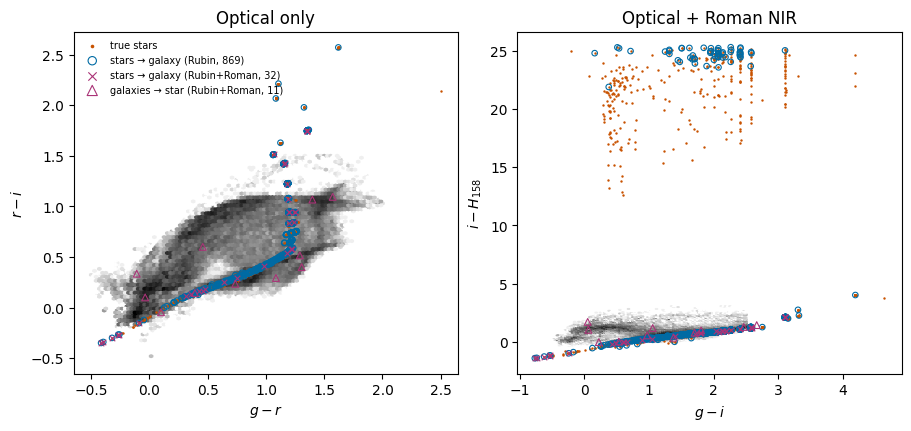

In [88]:
import matplotlib.pyplot as plt
C = {'Rubin': '#006BA4', 'Rubin+Roman': '#AA3377'}   # same run colors as plot_binned_metrics.RUN_COLORS
t = tab.dropna(subset=['H158'])
gal, star = t[t.truth_cls == 'g'], t[t.truth_cls == 's']
panels = [('mag_g', 'mag_r', 'mag_r', 'mag_i', r'$g-r$', r'$r-i$', 'Optical only'),
          ('mag_g', 'mag_i', 'mag_i', 'H158', r'$g-i$', r'$i-H_{158}$', 'Optical + Roman NIR')]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
for ax, (a, b, c, d, xl, yl, title) in zip(axes, panels):
    col = lambda f, x, y: f[x] - f[y]
    ax.hexbin(col(gal, a, b), col(gal, c, d), gridsize=90, bins='log', cmap='Greys', mincnt=1,
              extent=(-0.5, 2.5, -0.5, 3.5) if d == 'H158' else (-0.5, 2.0, -0.5, 1.5))
    ax.scatter(col(star, a, b), col(star, c, d), s=3, c='#C85200', lw=0, label='true stars')
    for lab, mk in [('Rubin', 'o'), ('Rubin+Roman', 'x')]:
        m = star[star[lab] == 'g']
        ax.scatter(col(m, a, b), col(m, c, d), s=16, marker=mk, facecolors='none' if mk == 'o' else C[lab],
                   edgecolors=C[lab], lw=0.8, label=f'stars → galaxy ({lab}, {len(m)})')
    fp = gal[gal['Rubin+Roman'] == 's']
    ax.scatter(col(fp, a, b), col(fp, c, d), s=24, marker='^', facecolors='none', edgecolors=C['Rubin+Roman'],
               lw=0.8, label=f'galaxies → star (Rubin+Roman, {len(fp)})')
    ax.set(xlabel=xl, ylabel=yl, title=title)
axes[0].legend(fontsize=7, loc='upper left', frameon=False, markerscale=1.5)
fig.savefig('paper_plots/star_galaxy_colors.png', dpi=200)


In [89]:
bad = t[(t.mag_i - t.H158) > 5]
print(len(bad), bad.truth_cls.value_counts().to_dict())
bad[['mag_i', 'mag_z', 'Y106', 'J129', 'H158']].describe()


340 {'s': 340}


,mag_i,mag_z,Y106,J129,H158
count,340.000000,340.000000,340.000000,340.000000,340.0
mean,21.955832,21.640172,12.294393,16.653105,0.0
std,2.715935,2.634478,10.746314,9.155139,0.0
min,12.635609,12.562832,0.000000,0.000000,0.0
25%,20.544545,20.361539,0.000000,16.386419,0.0
50%,22.602119,22.301510,17.860368,21.025541,0.0
75%,24.191157,23.737486,22.432278,23.048140,0.0
max,25.292641,25.240776,25.374111,25.620622,0.0


In [90]:
# 1. Does the Rubin -> Rubin+Roman gain come disproportionately from these stars?
zero = (tab[['Y106', 'J129', 'H158']] == 0).any(axis=1) | tab.H158.isna()
s = tab[tab.truth_cls == 's']
for name, sub in [('Roman mag = 0', s[zero[s.index]]), ('normal', s[~zero[s.index]])]:
    print(f"{name:14s} n={len(sub):5d}  " +
          '  '.join(f"{k}={(sub[k] == 's').mean():.3f}" for k in RUNS))


Roman mag = 0  n=  579  Rubin=0.817  RubinUps=0.834  Rubin+Roman=0.997
normal         n= 4509  Rubin=0.802  RubinUps=0.822  Rubin+Roman=0.993


In [91]:
# 2. Peak H158 pixel at a few of these stars vs normal stars of similar i-mag
def h158_peak(fn, ra, dec, box=3):
    p = Path(fn.replace('lsst_data', 'roman_data'))
    img = np.load(p)[2]                                   # H158 = channel 2 (Y106, J129, H158)
    r = pd.DataFrame(json.load(open(p.parent / f'truth_{p.stem}.json')))
    o = r.iloc[((r.ra - ra)**2 + (r.dec - dec)**2).idxmin()]
    y, x = int(round(o.cutout_y)), int(round(o.cutout_x))
    return img[max(y-box, 0):y+box+1, max(x-box, 0):x+box+1].max()

t0 = truth[truth.H158 == 0].sample(5, random_state=0)
tn = truth[(truth.truth_cls == 's') & (truth.H158 > 0) & truth.mag_i.between(t0.mag_i.min(), t0.mag_i.max())].sample(5, random_state=0)
for lab, df in [('H158=0', t0), ('normal', tn)]:
    print(lab, [(round(r.mag_i, 1), round(float(h158_peak(r.file_name, r.ra, r.dec)), 1)) for r in df.itertuples()])


H158=0 [(24.5, 157.0), (21.2, 977.1), (22.3, 1199.0), (22.5, 435.4), (18.2, 16729.4)]
normal [(24.1, 626.4), (22.7, 500.8), (23.8, 209.3), (22.6, 718.8), (19.7, 29242.1)]


In [93]:
stars.mag_i.describe()

count    5088.000000
mean       21.808063
std         2.694096
min         8.881651
25%        20.375196
50%        22.343979
75%        23.987795
max        25.296965
Name: mag_i, dtype: float64

In [92]:
rub_miss.mag_i.describe()

count    869.000000
mean      24.583552
std        0.798023
min       12.506410
25%       24.360371
50%       24.745157
75%       25.035372
max       25.296965
Name: mag_i, dtype: float64